Dataset Shape: (569, 30)

First Five Rows:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst radius  wor

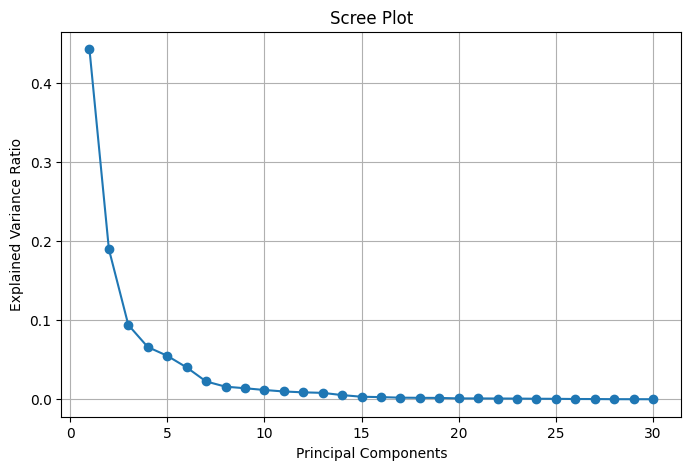

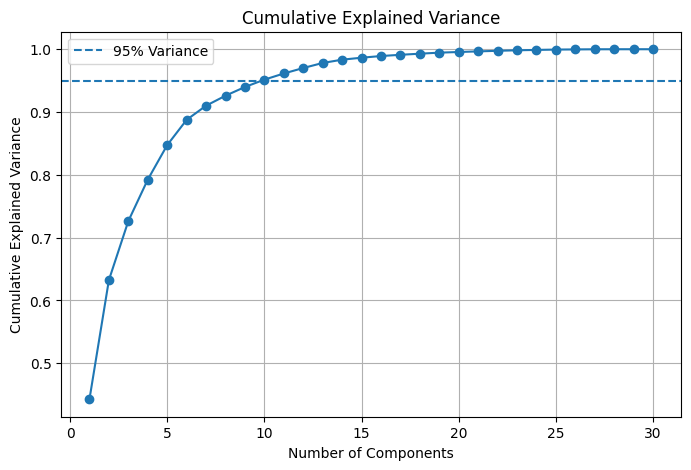


Number of Components for 95% Variance: 10
Retained Variance: 95.1568814336667 %

Reduced Dataset Shape: (569, 10)

Reconstruction MSE: 0.048431185663333244

Principal Component Loadings:
                              PC1       PC2       PC3       PC4       PC5  \
mean radius              0.218902 -0.233857 -0.008531 -0.041409 -0.037786   
mean texture             0.103725 -0.059706  0.064550  0.603050  0.049469   
mean perimeter           0.227537 -0.215181 -0.009314 -0.041983 -0.037375   
mean area                0.220995 -0.231077  0.028700 -0.053434 -0.010331   
mean smoothness          0.142590  0.186113 -0.104292 -0.159383  0.365089   
mean compactness         0.239285  0.151892 -0.074092 -0.031795 -0.011704   
mean concavity           0.258400  0.060165  0.002734 -0.019123 -0.086375   
mean concave points      0.260854 -0.034768 -0.025564 -0.065336  0.043861   
mean symmetry            0.138167  0.190349 -0.040240 -0.067125  0.305941   
mean fractal dimension   0.064363  0.36657

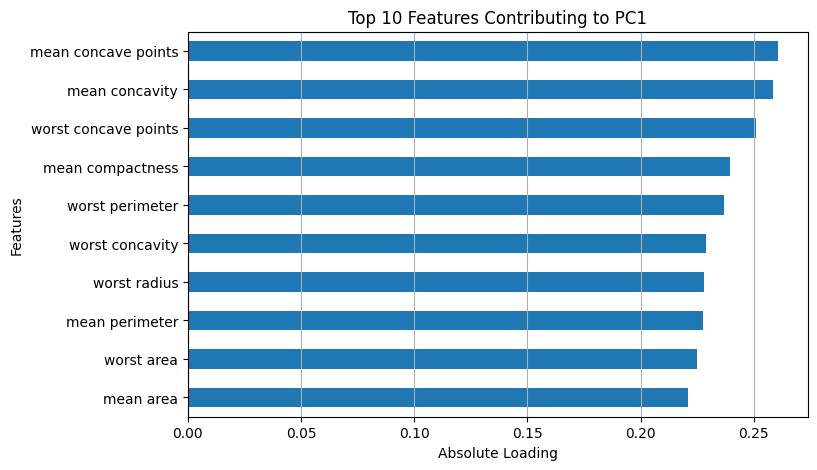


Final Results
----------------------------
Original Features: 30
Selected Components: 10
Information Retained: 95.1568814336667 %
Information Loss: 4.8431185663333025 %
Reconstruction MSE: 0.048431185663333244


In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error

# 1. Load Dataset
data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)

print("Dataset Shape:", X.shape)
print("\nFirst Five Rows:")
print(X.head())

# 2. Remove Target and Identifier Columns
X = X.select_dtypes(include=[np.number])

# 3. Standardize Features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 4. Apply PCA using all components
pca = PCA()
X_pca = pca.fit_transform(X_scaled)

# 5. Calculate Explained Variance
explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

print("\nExplained Variance Ratio:")
print(explained_variance)

print("\nCumulative Explained Variance:")
print(cumulative_variance)

# 6. Plot Scree Plot
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(explained_variance) + 1),
         explained_variance, marker='o')

plt.xlabel("Principal Components")
plt.ylabel("Explained Variance Ratio")
plt.title("Scree Plot")
plt.grid()
plt.show()

# 7. Plot Cumulative Explained Variance
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(cumulative_variance) + 1),
         cumulative_variance, marker='o')

plt.axhline(y=0.95, linestyle='--', label='95% Variance')
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("Cumulative Explained Variance")
plt.legend()
plt.grid()
plt.show()

# 8. Select Components Retaining 95% Variance
n_components = np.argmax(cumulative_variance >= 0.95) + 1

print("\nNumber of Components for 95% Variance:", n_components)
print("Retained Variance:",
      cumulative_variance[n_components - 1] * 100, "%")

# 9. Project Data into Reduced Dimensions
pca_reduced = PCA(n_components=n_components)
X_reduced = pca_reduced.fit_transform(X_scaled)

print("\nReduced Dataset Shape:", X_reduced.shape)

# 10. Reconstruct Original Standardized Features
X_reconstructed = pca_reduced.inverse_transform(X_reduced)

# 11. Calculate Reconstruction MSE
mse = mean_squared_error(X_scaled, X_reconstructed)

print("\nReconstruction MSE:", mse)

# 12. Inspect Principal Component Loadings
loadings = pd.DataFrame(
    pca_reduced.components_.T,
    index=X.columns,
    columns=[f"PC{i+1}" for i in range(n_components)]
)

print("\nPrincipal Component Loadings:")
print(loadings)

# 13. Identify Most Influential Features in PC1
pc1_features = loadings["PC1"].abs().sort_values(ascending=False)

print("\nTop 10 Influential Features in PC1:")
print(pc1_features.head(10))

# 14. Visualize Top Features in PC1
pc1_features.head(10).sort_values().plot(
    kind='barh', figsize=(8, 5)
)

plt.xlabel("Absolute Loading")
plt.ylabel("Features")
plt.title("Top 10 Features Contributing to PC1")
plt.grid(axis='x')
plt.show()

# 15. Display Information Retention and Loss
information_retained = cumulative_variance[n_components - 1] * 100
information_loss = 100 - information_retained

print("\nFinal Results")
print("----------------------------")
print("Original Features:", X.shape[1])
print("Selected Components:", n_components)
print("Information Retained:", information_retained, "%")
print("Information Loss:", information_loss, "%")
print("Reconstruction MSE:", mse)
